In [1]:
import pandas as pd
import numpy as np
import os, re
import itertools
from IPython.display import display
from scipy import stats

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
import scikit_posthocs as sp

Key Variables:
- data: contains the results of the experiment (i.e. energy usage values)
- labels: the list of considered compression algorithm
- groups: results aggregated by run
- samples: sizes after compression with each algorithm

# Constants

In [3]:
EXTENSIONS = {
    'npm': '.tgz',
    'xz': '.tar.xz',
    'brotli': '.tar.br',
    'zstd': '.tar.zst',
    'zopfli': '.tgz'
}
sample_dir = '../pkgs/samples'
data_path = '../results/npm-exp/run_table.csv'

# Reading Results

In [4]:
data = pd.read_csv(data_path)
data['energy-total'] = (data['energy-pkg'] + data['energy-ram']) / 3.6 # J -> mWh
data = data.rename(columns={'subject' : 'name'})
len(data)

9450

In [5]:
# labels = data['alg'].unique()
labels = ["npm", "brotli", "xz", "zopfli", "zstd"]

In [6]:
# dict containing dataframe of packages' sizes before decompression
samples = {k : pd.read_csv(f'{sample_dir}/{k}.csv') for k in labels}
sizes = pd.concat(samples.values(),join='inner', ignore_index=True)
sizes

,name,size,_key
0,npm/watchpack-chokidar2--watchpack-chokidar2-2...,357,watchpack-chokidar2--watchpack-chokidar2-2.0.1
1,npm/client-only--client-only-0.0.1.tgz,481,client-only--client-only-0.0.1
2,npm/babel-helper-get-function-arity--babel-hel...,790,babel-helper-get-function-arity--babel-helper-...
3,npm/@types__uuid--uuid-11.0.0.tgz,1138,@types__uuid--uuid-11.0.0
4,npm/@types__glob--glob-9.0.0.tgz,1150,@types__glob--glob-9.0.0
...,...,...,...
310,zstd/webpack--webpack-5.107.1.tar.zst,883757,webpack--webpack-5.107.1
311,zstd/whatwg-mimetype--whatwg-mimetype-5.0.0.ta...,10528,whatwg-mimetype--whatwg-mimetype-5.0.0
312,zstd/workbox-routing--workbox-routing-7.4.1.ta...,40883,workbox-routing--workbox-routing-7.4.1
313,zstd/workbox-streams--workbox-streams-7.4.1.ta...,25830,workbox-streams--workbox-streams-7.4.1


# Merge the results and the sizes dataframes

In [7]:
data.astype({"name": "str"}).dtypes
data = data.merge(sizes, on='name')

# Data Preprocessing

In [8]:
def clean_name(path: str) -> str:
    # Remove everything up to the last "/"
    base = os.path.basename(path)
    base = re.sub(r'\.tar(\.[a-zA-Z0-9]+)?$|\.tgz$', '', base)
    return base

In [9]:
def true_stem(p: str) -> str:
    name = os.path.basename(p)
    for ext in list(EXTENSIONS.values()):
        if name.endswith(ext):
            return name[: -len(ext)]
    return name.stem
    # return p.stem

## Split run number and ID 

In [10]:
# Preprocessing to split run and rep id; Step not needed in the next version of Experiment Runner 
import re

run_ids = data['__run_id'].to_list()
def extract_run_reps(run_ids):
    run_reps = []
 
    for rid in run_ids:
        run, reps = re.findall(r'\d+', rid)
        run_reps.append({'__run_id' : rid, 'run' : run, 'reps' : reps})
 
    return run_reps

run_reps = extract_run_reps(run_ids)
df_run_reps = pd.DataFrame(run_reps)
data = pd.merge(data, df_run_reps, on=['__run_id'])
data.head()

,__run_id,__done,alg,name,energy-pkg,energy-ram,execution-time,energy-total,size,_key,run,reps
0,run_206_repetition_11,DONE,zstd,zstd/babel-plugin-check-es2015-constants--babe...,0.26,0.03,0.003511,0.080556,1588,babel-plugin-check-es2015-constants--babel-plu...,206,11
1,run_73_repetition_12,DONE,xz,xz/@sindresorhus__is--is-8.1.0.tar.xz,0.41,0.05,0.005875,0.127778,21212,@sindresorhus__is--is-8.1.0,73,12
2,run_251_repetition_20,DONE,zstd,zstd/xml2js--xml2js-0.6.2.tar.zst,0.97,0.11,0.014525,0.300000,704787,xml2js--xml2js-0.6.2,251,20
3,run_220_repetition_11,DONE,zstd,zstd/iconv-lite--iconv-lite-0.7.2.tar.zst,0.36,0.04,0.005436,0.111111,156893,iconv-lite--iconv-lite-0.7.2,220,11
4,run_143_repetition_13,DONE,zopfli,zopfli/babel-plugin-check-es2015-constants--ba...,0.26,0.03,0.004009,0.080556,1638,babel-plugin-check-es2015-constants--babel-plu...,143,13


# Correlation Energy - Time - Size

In [11]:
# get the medians of the three metrics of interest
medians = data.groupby(['alg', 'run'])[['energy-total', 'execution-time', 'size']].median()
medians_result = {
    alg: group.to_dict(orient="list") 
    for alg, group in medians.droplevel("run").groupby("alg")
}

for a in labels:
    alg_data = medians_result[a]
    for x in ["execution-time", "size"]:
        rho, p = spearmanr(alg_data[x], alg_data["energy-total"])
        print(f"{a:6s} {x:15s} rho = {rho:.4f}, p = {p:.2e}")

npm    execution-time  rho = 0.9926, p = 1.31e-57
npm    size            rho = 0.9673, p = 4.86e-38
brotli execution-time  rho = 0.9898, p = 2.28e-53
brotli size            rho = 0.9838, p = 3.13e-47
xz     execution-time  rho = 0.9973, p = 5.35e-71
xz     size            rho = 0.9958, p = 5.40e-65
zopfli execution-time  rho = 0.9827, p = 2.37e-46
zopfli size            rho = 0.9834, p = 6.51e-47
zstd   execution-time  rho = 0.9842, p = 1.44e-47
zstd   size            rho = 0.9768, p = 1.48e-42


# Data analysis

In [12]:
energy_groups = data.groupby(['alg', 'run'])['energy-total']
groups = energy_groups.describe()
groups['cv'] = groups['std'] / groups['mean']

# medians
values = [
    groups.xs(k, level='alg')['50%'].tolist() for k in labels 
]

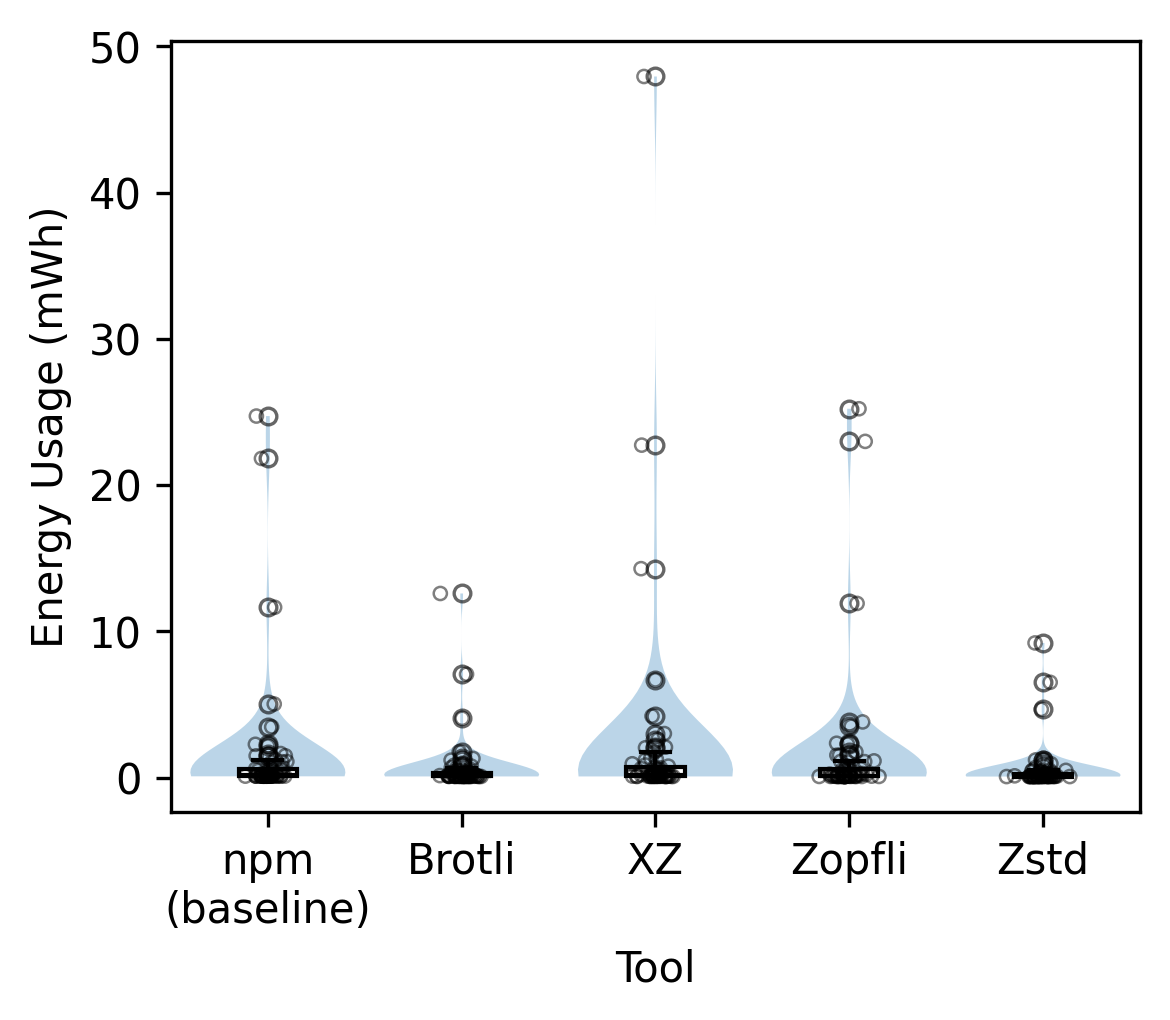

In [13]:
#plt.figure(figsize=(10, 5.7), dpi=300)
plt.figure(figsize=(4, 3.5), dpi=300)

positions = range(1, len(labels) + 1)

vp = plt.violinplot(values, positions=positions, widths=0.8,
                     showmeans=False, showextrema=False, showmedians=False)
bp = plt.boxplot(values, positions=positions, widths=0.3,
                  patch_artist=True)

plt.setp(bp['fliers'], marker='o', markersize=4,
          markerfacecolor='none',  
          markeredgecolor='black',
          markeredgewidth=0.8,
          alpha=0.6)

for element in ['whiskers', 'fliers', 'means', 'medians', 'caps']:
    plt.setp(bp[element], color='black')
for box in bp['boxes']:
    box.set(facecolor='white', edgecolor='black')

# overlay all raw points with jitter
rng = np.random.default_rng(0)
for pos, y in zip(positions, values):
    x = rng.normal(pos, 0.05, size=len(y))  # small horizontal jitter
    plt.scatter(x, y, s=10, facecolors='none', edgecolors='black',
                linewidths=0.6, alpha=0.5, zorder=3)

plt.xticks(positions,["npm\n(baseline)", "Brotli", "XZ", "Zopfli", "Zstd"])

plt.xlabel("Tool")
plt.ylabel("Energy Usage (mWh)")
plt.tight_layout()

plt.savefig('groups.pdf')
# plt.show()

## Statistical Analysis

In [14]:
df_agg = (
    data.groupby(["alg", "_key"])['energy-total'].describe().drop(columns='count')
)
df_agg

mean       std  \
alg    _key                                                                     
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...  0.160370  0.005050   
       @babel__plugin-transform-regexp-modifiers--plug...  0.081944  0.008016   
       @esbuild__linux-ia32--linux-ia32-0.28.0             1.758889  0.014339   
       @eslint__eslintrc--eslintrc-3.3.5                   0.131667  0.007775   
       @ethersproject__abstract-signer--abstract-signe...  0.093519  0.009576   
...                                                             ...       ...   
zstd   webpack--webpack-5.107.1                            0.475556  0.005944   
       whatwg-mimetype--whatwg-mimetype-5.0.0              0.075093  0.005335   
       workbox-routing--workbox-routing-7.4.1              0.096389  0.006490   
       workbox-streams--workbox-streams-7.4.1              0.086389  0.005806   
       xml2js--xml2js-0.6.2                                0.300833  0.013052   

                                                                min       25%  \
alg    _key                                                                     
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...  0.150000  0.158333   
       @babel__plugin-transform-regexp-modifiers--plug...  0.058333  0.077778   
       @esbuild__linux-ia32--linux-ia32-0.28.0             1.733333  1.747222   
       @eslint__eslintrc--eslintrc-3.3.5                   0.119444  0.128472   
       @ethersproject__abstract-signer--abstract-signe...  0.077778  0.088889   
...                                                             ...       ...   
zstd   webpack--webpack-5.107.1                            0.463889  0.470139   
       whatwg-mimetype--whatwg-mimetype-5.0.0              0.058333  0.072222   
       workbox-routing--workbox-routing-7.4.1              0.086111  0.088889   
       workbox-streams--workbox-streams-7.4.1              0.077778  0.080556   
       xml2js--xml2js-0.6.2                                0.283333  0.294444   

                                                                50%       75%  \
alg    _key                                                                     
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...  0.158333  0.161111   
       @babel__plugin-transform-regexp-modifiers--plug...  0.080556  0.086806   
       @esbuild__linux-ia32--linux-ia32-0.28.0             1.762500  1.768750   
       @eslint__eslintrc--eslintrc-3.3.5                   0.130556  0.137500   
       @ethersproject__abstract-signer--abstract-signe...  0.091667  0.100000   
...                                                             ...       ...   
zstd   webpack--webpack-5.107.1                            0.476389  0.477778   
       whatwg-mimetype--whatwg-mimetype-5.0.0              0.075000  0.080556   
       workbox-routing--workbox-routing-7.4.1              0.100000  0.100000   
       workbox-streams--workbox-streams-7.4.1              0.088889  0.088889   
       xml2js--xml2js-0.6.2                                0.297222  0.305556   

                                                                max  
alg    _key                                                          
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...  0.169444  
       @babel__plugin-transform-regexp-modifiers--plug...  0.100000  
       @esbuild__linux-ia32--linux-ia32-0.28.0             1.788889  
       @eslint__eslintrc--eslintrc-3.3.5                   0.150000  
       @ethersproject__abstract-signer--abstract-signe...  0.111111  
...                                                             ...  
zstd   webpack--webpack-5.107.1                            0.488889  
       whatwg-mimetype--whatwg-mimetype-5.0.0              0.080556  
       workbox-routing--workbox-routing-7.4.1              0.111111  
       workbox-streams--workbox-streams-7.4.1              0.100000  
       xml2js--xml2js-0.6.2                                0.

In [15]:
# ------------------------------------------------------------------
# Descriptives (median + IQR per group)
# ------------------------------------------------------------------
desc = data.groupby('alg')['energy-total'].describe().drop(columns='count')
desc['cv'] = desc['std'] / desc['mean']
desc.T.style.format('{:.10f}')

alg,brotli,npm,xz,zopfli,zstd
mean,0.6229541446,1.4229174015,1.9486669606,1.4261331570,0.5245928865
std,1.8311079210,4.2884677993,6.7648696010,4.4225624042,1.4894294312
min,0.0583333333,0.0694444444,0.0583333333,0.0583333333,0.0500000000
25%,0.0888888889,0.1027777778,0.0916666667,0.0805555556,0.0777777778
50%,0.1111111111,0.1472222222,0.1583333333,0.1305555556,0.1000000000
75%,0.3305555556,0.6409722222,0.7750000000,0.6305555556,0.2909722222
max,12.7194444444,24.8888888889,48.2111111111,25.3111111111,9.4222222222
cv,2.9393943949,3.0138557549,3.4715370752,3.1010865869,2.8392101178


In [16]:
# Exclude baseline from the comparison as 'npm' is a fixed cost
# group_sub = data.groupby(['alg'])[['energy-total', '_key']].apply(list)
df_agg = (
    data.groupby(["alg", "_key"])['energy-total']
    .median()
    .reset_index()
    .sort_values("_key")
)
df_pivot = df_agg.pivot(index="_key", columns="alg", values="energy-total")
N, k = df_pivot.shape
df_pivot.head()

alg,brotli,npm,xz,zopfli,zstd
_key,,,,,
@aws-cdk__cloud-assembly-schema--cloud-assembly-schema-53.27.0,0.158333,0.219444,0.308333,0.216667,0.127778
@babel__plugin-transform-regexp-modifiers--plugin-transform-regexp-modifiers-7.28.6,0.080556,0.100000,0.080556,0.080556,0.072222
@esbuild__linux-ia32--linux-ia32-0.28.0,1.762500,2.277778,6.680556,2.348611,0.952778
@eslint__eslintrc--eslintrc-3.3.5,0.130556,0.197222,0.208333,0.186111,0.109722
@ethersproject__abstract-signer--abstract-signer-5.8.0,0.091667,0.111111,0.102778,0.091667,0.080556


In [17]:
# ------------------------------------------------------------------
# Shapiro-Wilk normality test (per group)
# ------------------------------------------------------------------
print("Shapiro-Wilk normality test per group")

for col in df_pivot.columns:
    stat, p_val = stats.shapiro(df_pivot[col])
    print(f"Format: {col:12s} | p-value: {p_val:.20f} "
          f"({'Normal' if p_val > 0.05 else 'Non-normal'})")

Shapiro-Wilk normality test per group
Format: brotli       | p-value: 0.00000000000000122677 (Non-normal)
Format: npm          | p-value: 0.00000000000000200004 (Non-normal)
Format: xz           | p-value: 0.00000000000000071022 (Non-normal)
Format: zopfli       | p-value: 0.00000000000000164536 (Non-normal)
Format: zstd         | p-value: 0.00000000000000170250 (Non-normal)


In [18]:
alg_data = [df_pivot[col].values for col in df_pivot.columns]
stat, p_value = stats.friedmanchisquare(*alg_data)

print("\n--- Friedman Test Result ---")
print(f"Friedman chi-squared statistic: {stat:.4f}")
print(f"p-value: {p_value:.4e}")

if p_value < 0.05:
    print("Result: Statistically significant difference between compression formats (p < 0.05).\n")
else:
    print("Result: No statistically significant difference found.\n")

# --- Overall Effect Size: Kendall's W ---
kendall_w = stat / (N * (k - 1))
print(f"Kendall's W (Effect Size): {kendall_w:.4f}")


--- Friedman Test Result ---
Friedman chi-squared statistic: 191.0370
p-value: 3.1729e-40
Result: Statistically significant difference between compression formats (p < 0.05).

Kendall's W (Effect Size): 0.7581


In [28]:
from scipy.optimize import brentq

def friedman_power_from_W(W, N, k, alpha=0.05):
    crit = stats.chi2.ppf(1 - alpha, k - 1)
    lam = N * (k - 1) * W
    return 1 - stats.ncx2.cdf(crit, k - 1, lam)

def min_detectable_W(N, k, alpha=0.05, power=0.80):
    return brentq(lambda W: friedman_power_from_W(W, N, k, alpha) - power, 1e-6, 1.0)

def required_N(W, k, alpha=0.05, power=0.80):
    n = 3
    while friedman_power_from_W(W, n, k, alpha) < power:
        n += 1
    return n

N, k = 63, 5
print(f"Minimum detectable Kendall's W at N={N}, k={k}, power=0.80: "
      f"{min_detectable_W(N, k):.4f}")

# Power for conventional effect sizes (Kendall's W: ~0.1 small, ~0.3 medium, ~0.5 large)
for W in [0.05, 0.10, 0.20, 0.30, 0.50]:
    print(f"W={W:.2f}: power={friedman_power_from_W(W, N, k):.3f}, "
          f"N needed for 80% = {required_N(W, k)}")

Minimum detectable Kendall's W at N=63, k=5, power=0.80: 0.0474
W=0.05: power=0.824, N needed for 80% = 60
W=0.10: power=0.990, N needed for 80% = 30
W=0.20: power=1.000, N needed for 80% = 15
W=0.30: power=1.000, N needed for 80% = 10
W=0.50: power=1.000, N needed for 80% = 6


In [19]:
# ------------------------------------------------------------------
# Paired Wilcoxon signed-rank with Holm correction
# ------------------------------------------------------------------
if p_value < 0.05:
    # scikit-posthocs handles pairwise paired tests with correction
    posthoc_p_values = sp.posthoc_wilcoxon(
        df_agg, 
        val_col="energy-total", 
        group_col="alg",
        p_adjust="holm"
    )
    
    print("--- Post-Hoc Pairwise Adjusted p-values (Holm-Bonferroni) ---")
    print(posthoc_p_values.round(15))
    # print(posthoc_p_values.round(15).to_latex())

--- Post-Hoc Pairwise Adjusted p-values (Holm-Bonferroni) ---
              brotli           npm          zstd            xz        zopfli
brotli  1.000000e+00  4.820700e-11  1.947734e-09  2.568727e-09  2.237763e-06
npm     4.820700e-11  1.000000e+00  4.820700e-11  5.679327e-01  4.040142e-02
zstd    1.947734e-09  4.820700e-11  1.000000e+00  4.820700e-11  4.820700e-11
xz      2.568727e-09  5.679327e-01  4.820700e-11  1.000000e+00  4.371744e-04
zopfli  2.237763e-06  4.040142e-02  4.820700e-11  4.371744e-04  1.000000e+00


In [20]:
from itertools import combinations

def rank_biserial(x, y):
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]
    ranks = stats.rankdata(np.abs(d))
    w_plus, w_minus = ranks[d > 0].sum(), ranks[d < 0].sum()
    return (w_plus - w_minus) / (w_plus + w_minus)

algs = list(df_pivot.columns)
rb = pd.DataFrame(0.0, index=algs, columns=algs)

for a, b in combinations(algs, 2):
    pair = df_pivot[[a, b]].dropna()
    r = rank_biserial(pair[a], pair[b])
    rb.loc[a, b], rb.loc[b, a] = r, -r

print("--- Rank-biserial correlation (row vs column; positive = row has higher energy) ---")
print(rb.round(15))
#print(rb.round(15).to_latex())

--- Rank-biserial correlation (row vs column; positive = row has higher energy) ---
          brotli       npm        xz    zopfli      zstd
brotli  0.000000 -1.000000 -1.000000 -0.847364  0.909722
npm     1.000000  0.000000 -0.084082  0.336310  1.000000
xz      1.000000  0.084082  0.000000  0.578342  1.000000
zopfli  0.847364 -0.336310 -0.578342  0.000000  1.000000
zstd   -0.909722 -1.000000 -1.000000 -1.000000  0.000000


# Weighted Energy Savings (Discussion Section)

In [21]:
weights = pd.read_csv('top_2500_depended_enriched.csv')[
                ['PackageName', 'DownloadsLastWeek', 'DownloadsLastMonth', 'DownloadsLastYear', 'DistTarball']
]

weights['_key'] = weights['DistTarball'].apply(
    lambda x: f'{os.path.basename(x)}'
)
# npm_data = data[data['alg'] == 'npm']
#weights

In [22]:
import re

weights['_key_norm'] = weights['_key'].str.replace(r'\.tgz$', '', regex=True)


npm_data = data.groupby(['alg', '_key']).median(numeric_only=True).reset_index()
npm_data['_key_norm'] = npm_data['_key'].str.split('--', n=1).str[-1]

wd = npm_data.merge(weights, on='_key_norm', how='left', suffixes=('', '_w'))
#wd = wd.rename(columns={'energy-total' : 'energy-decompression'})
wd['energy-week'] = wd['DownloadsLastWeek'] * wd['energy-total']
wd['energy-month'] = wd['DownloadsLastMonth'] * wd['energy-total']
wd['energy-year'] = wd['DownloadsLastYear'] * wd['energy-total']
# wd.to_csv('wd.csv')
#merged.groupby('_key_norm').describe()
#merged[['_key_norm', 'energy-total', 'DownloadsLastWeek', 'DownloadsLastMonth', 'DownloadsLastYear']]
npm_data

,alg,_key,energy-pkg,energy-ram,execution-time,energy-total,size,_key_norm
0,brotli,@aws-cdk__cloud-assembly-schema--cloud-assembl...,0.510,0.06,0.007751,0.158333,112877.0,cloud-assembly-schema-53.27.0
1,brotli,@babel__plugin-transform-regexp-modifiers--plu...,0.260,0.03,0.003943,0.080556,1825.0,plugin-transform-regexp-modifiers-7.28.6
2,brotli,@esbuild__linux-ia32--linux-ia32-0.28.0,5.670,0.67,0.088463,1.762500,3514848.0,linux-ia32-0.28.0
3,brotli,@eslint__eslintrc--eslintrc-3.3.5,0.420,0.05,0.006394,0.130556,54972.0,eslintrc-3.3.5
4,brotli,@ethersproject__abstract-signer--abstract-sign...,0.300,0.03,0.004497,0.091667,12188.0,abstract-signer-5.8.0
...,...,...,...,...,...,...,...,...
310,zstd,webpack--webpack-5.107.1,1.535,0.18,0.022811,0.476389,883757.0,webpack-5.107.1
311,zstd,whatwg-mimetype--whatwg-mimetype-5.0.0,0.240,0.03,0.003580,0.075000,10528.0,whatwg-mimetype-5.0.0
312,zstd,workbox-routing--workbox-routing-7.4.1,0.320,0.04,0.004523,0.100000,40883.0,workbox-routing-7.4.1
313,zstd,workbox-streams--workbox-streams-7.4.1,0.290,0.03,0.004103,0.088889,25830.0,workbox-streams-7.4.1


In [23]:
npm_data.groupby(['alg', '_key']).median(numeric_only=True)

energy-pkg  \
alg    _key                                                             
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...       0.510   
       @babel__plugin-transform-regexp-modifiers--plug...       0.260   
       @esbuild__linux-ia32--linux-ia32-0.28.0                  5.670   
       @eslint__eslintrc--eslintrc-3.3.5                        0.420   
       @ethersproject__abstract-signer--abstract-signe...       0.300   
...                                                               ...   
zstd   webpack--webpack-5.107.1                                 1.535   
       whatwg-mimetype--whatwg-mimetype-5.0.0                   0.240   
       workbox-routing--workbox-routing-7.4.1                   0.320   
       workbox-streams--workbox-streams-7.4.1                   0.290   
       xml2js--xml2js-0.6.2                                     0.960   

                                                           energy-ram  \
alg    _key                                                             
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...        0.06   
       @babel__plugin-transform-regexp-modifiers--plug...        0.03   
       @esbuild__linux-ia32--linux-ia32-0.28.0                   0.67   
       @eslint__eslintrc--eslintrc-3.3.5                         0.05   
       @ethersproject__abstract-signer--abstract-signe...        0.03   
...                                                               ...   
zstd   webpack--webpack-5.107.1                                  0.18   
       whatwg-mimetype--whatwg-mimetype-5.0.0                    0.03   
       workbox-routing--workbox-routing-7.4.1                    0.04   
       workbox-streams--workbox-streams-7.4.1                    0.03   
       xml2js--xml2js-0.6.2                                      0.11   

                                                           execution-time  \
alg    _key                                                                 
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...        0.007751   
       @babel__plugin-transform-regexp-modifiers--plug...        0.003943   
       @esbuild__linux-ia32--linux-ia32-0.28.0                   0.088463   
       @eslint__eslintrc--eslintrc-3.3.5                         0.006394   
       @ethersproject__abstract-signer--abstract-signe...        0.004497   
...                                                                   ...   
zstd   webpack--webpack-5.107.1                                  0.022811   
       whatwg-mimetype--whatwg-mimetype-5.0.0                    0.003580   
       workbox-routing--workbox-routing-7.4.1                    0.004523   
       workbox-streams--workbox-streams-7.4.1                    0.004103   
       xml2js--xml2js-0.6.2                                      0.014383   

                                                           energy-total  \
alg    _key                                                               
brotli @aws-cdk__cloud-assembly-schema--cloud-assembly...      0.158333   
       @babel__plugin-transform-regexp-modifiers--plug...      0.080556   
       @esbuild__linux-ia32--linux-ia32-0.28.0                 1.762500   
       @eslint__eslintrc--eslintrc-3.3.5                       0.130556   
       @ethersproject__abstract-signer--abstract-signe...      0.091667   
...                                                                 ...   
zstd   webpack--webpack-5.107.1                                0.476389   
       whatwg-mimetype--whatwg-mimetype-5.0.0                  0.075000   
       workbox-routing--workbox-routing-7.4.1                  0.100000   
       workbox-streams--workbox-streams-7.4.1                  0.088889   
       xml2js--xml2js-0.6.2                                    0.297222   

                                                                size  
alg    _key                                                           
brotli @aws-cdk__cloud-assembly-schema-

## Estimate network energy for the 63 packages

In [24]:
E_MB = 0.05 * 1000          # 0.05 Wh/MB -> 50 mWh/MB
BYTES_PER_MB = 1e6          # check: use 1024**2 if your paper uses MiB; skip if 'size' is already in MB

periods = {
    "week":  "DownloadsLastWeek",
    "month": "DownloadsLastMonth",
    "year":  "DownloadsLastYear",
}

wd["size_mb"] = wd["size"] / BYTES_PER_MB

# Eq. (3): E(c) = e_MB * sum_p S_c(p) * D_p  (per row = per package)

for p, dl in periods.items():
    wd[f"transfer-{p}"] = E_MB * wd["size_mb"] * wd[dl]                    # mWh
    wd[f"total-{p}"]    = wd[f"transfer-{p}"] + wd[f"energy-{p}"]          # transfer + decompression, mWh
#
wd
# Eq. (4): saving vs. the original archive (the npm rows), per package
orig_size_mb = (wd[wd["alg"] == "npm"]
                .drop_duplicates("_key_norm")      # in case of repeated runs
                .set_index("_key_norm")["size_mb"])
wd["size_orig_mb"] = wd["_key_norm"].map(orig_size_mb)
#
for p, dl in periods.items():
    wd[f"transfer-saving-{p}"] = E_MB * (wd["size_orig_mb"] - wd["size_mb"]) * wd[dl]   # mWh

In [25]:
periods = ["week", "month", "year"]
order   = ["npm", "zstd", "brotli", "xz", "zopfli"]
SCALE   = 1e9

dec_cols      = [f"energy-{p}"   for p in periods]   # decompression energy
transfer_cols = [f"transfer-{p}" for p in periods]   # transfer energy only
total_cols    = [f"total-{p}"    for p in periods]   # total energy (used for the saving)

g = wd.groupby("alg")[dec_cols + transfer_cols + total_cols].sum().reindex(order) / SCALE

# Saving = total energy (npm) - total energy (tool); positive = energy saved
saving = g.loc["npm", total_cols] - g[total_cols]
saving.columns = [f"saving-{p}" for p in periods]

tab = pd.concat([g[dec_cols], g[transfer_cols], saving], axis=1)
tab.loc["npm", saving.columns] = float("nan")     # baseline has no saving
tab = tab.reset_index().rename(columns={"alg": "Tool"})

# Round all numeric columns to 3 decimals
num_cols = tab.columns[1:]
tab[num_cols] = tab[num_cols].round(3)

# Multi-level header
tab.columns = pd.MultiIndex.from_tuples(
    [("", "Tool")]
    + [("Decompression energy (GWh)", p.capitalize()) for p in periods]
    + [("Transfer energy (GWh)",      p.capitalize()) for p in periods]
    + [("Total energy saving vs. npm (GWh)", p.capitalize()) for p in periods]
)
print(tab.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# ---- LaTeX (IEEE style, booktabs) ----
def fmt(x):
    return "--" if pd.isna(x) else f"{x:,.2f}"

rows = []
for _, r in tab.iterrows():
    v = r.values
    cells = [v[0]] + [fmt(x) for x in v[1:]]
    rows.append(" & ".join(cells) + r" \\")

latex = r"""\begin{table*}[t]
\centering
\caption{Estimated decompression and transfer energy per week, month and year for each compression tool, and the saving in total energy relative to the npm baseline.}
\label{tab:energy-summary}
\begin{tabular}{lrrrrrrrrr}
\toprule
 & \multicolumn{3}{c}{Decompression energy (GWh)} & \multicolumn{3}{c}{Transfer energy (GWh)} & \multicolumn{3}{c}{Total saving vs. npm (GWh)} \\
\cmidrule(lr){2-4} \cmidrule(lr){5-7} \cmidrule(lr){8-10}
Tool & Week & Month & Year & Week & Month & Year & Week & Month & Year \\
\midrule
""" + "\n".join(rows) + r"""
\bottomrule
\end{tabular}
\end{table*}"""
print(latex)

       Decompression energy (GWh)              Transfer energy (GWh)                Total energy saving vs. npm (GWh)               
  Tool                       Week Month   Year                  Week  Month    Year                              Week  Month    Year
   npm                       3.31 13.25  98.32                191.19 765.14 5739.62                               NaN    NaN     NaN
  zstd                       1.13  4.52  34.01                 80.53 322.65 2485.25                            112.84 451.23 3318.68
brotli                       1.27  5.08  38.37                 81.14 325.02 2499.74                            112.09 448.30 3299.83
    xz                       3.51 14.06 107.33                 79.19 317.31 2440.74                            111.80 447.03 3289.86
zopfli                       3.21 12.87  96.00                187.59 750.80 5618.68                              3.69  14.72  123.26
\begin{table*}[t]
\centering
\caption{Estimated decompression and tra

## Single Decompression Improvement

In [26]:
# -----------------------------------------------
# PER-PACKAGE PERCENTAGE IMPROVEMENT (Paired)
# -------------------------------------------------------------------
# Calculates (npm - alg) / npm * 100 for each individual package
df_pct_diff = df_pivot.apply(
    lambda col: ((df_pivot["npm"] - col) / df_pivot["npm"]) * 100
)

# Focus on algorithms with large effect sizes relative to npm
target_algs = ["brotli", "zstd", "zopfli", "xz"]  

improvement_summary = pd.DataFrame({
    "Median % Savings": df_pct_diff[target_algs].median(),
    "Mean % Savings": df_pct_diff[target_algs].mean(),
    "25th Percentile": df_pct_diff[target_algs].quantile(0.25),
    "75th Percentile": df_pct_diff[target_algs].quantile(0.75),
})

print("--- Percentage Energy Improvement Relative to npm Baseline ---")
print(improvement_summary.round(2))

--- Percentage Energy Improvement Relative to npm Baseline ---
        Median % Savings  Mean % Savings  25th Percentile  75th Percentile
alg                                                                       
brotli             23.40           30.80            17.84            45.10
zstd               34.43           41.72            27.78            57.43
zopfli             10.53           10.43             0.44            19.44
xz                  2.27          -12.88           -22.01            12.31


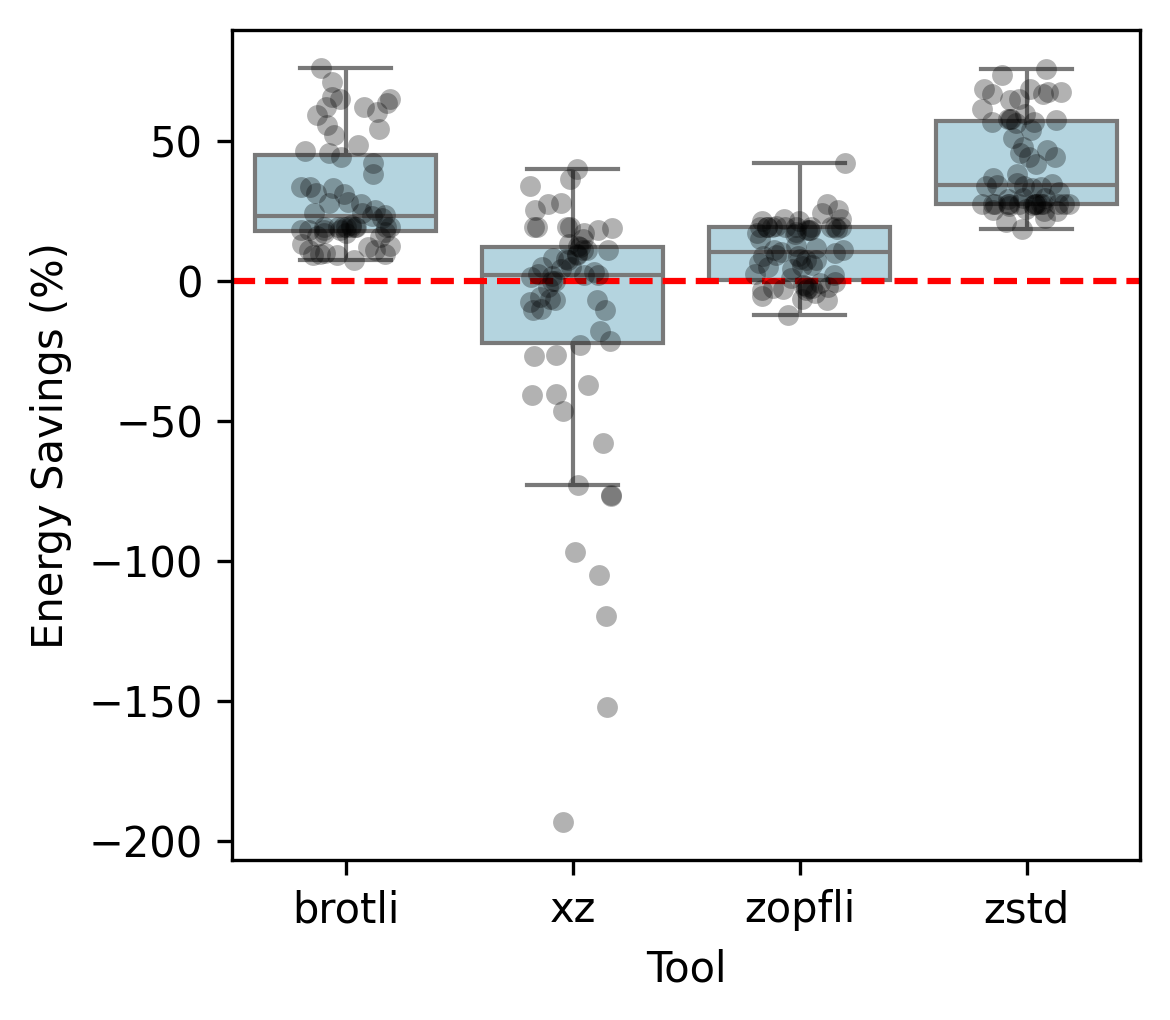

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Calculate direct ENERGY SAVINGS (%)
# Positive = Saved energy | Negative = Wasted energy / worse than npm
df_savings = df_pivot.apply(
    lambda col: ((df_pivot["npm"] - col) / df_pivot["npm"]) * 100
)

# Exclude npm column since savings for npm vs npm is always 0
df_savings_filtered = df_savings.drop(columns=["npm"]).melt(
    var_name="Tool", value_name="Energy Savings vs. npm Baseline (%)"
)

# plt.figure(figsize=(8, 2.5), dpi=300)
plt.figure(figsize=(4, 3.5), dpi=300)

# Plot boxplot and stripplot
ax = sns.boxplot(
    data=df_savings_filtered, 
    x="Tool", 
    y="Energy Savings vs. npm Baseline (%)", 
    color="lightblue",
    showfliers=False
)
sns.stripplot(
    data=df_savings_filtered,
    x="Tool", 
    y="Energy Savings vs. npm Baseline (%)", 
    color="black", 
    alpha=0.3, 
    jitter=0.2
)

# Reference line at 0% (npm baseline performance)
plt.axhline(0, color="red", linestyle="--", linewidth=1.5, label="npm Baseline (0% Savings)")

plt.ylabel("Energy Savings (%)")
# plt.ylabel("Energy Savings (%) [Higher is Better]")
# plt.title("Package Decompression Energy Savings Relative to npm Baseline")
# plt.legend(loc="upper right")
plt.tight_layout()
plt.savefig('savings.pdf')
# plt.show()